# Analiza kryteriów wykluczenia i ograniczeń strukturalnych dla hipotez H1–H5

Chociaż wszystkie 5 hipotez posiada swoje teoretyczne byty w tabelach (są w pełni połączalne relacyjnie), **H3 i H4 są obarczone wysokim ryzykiem lub warunkowo niewykonalne w pierwotnie planowanej formie** ze względu na kryteria wykluczenia zdefiniowane w [docs/rentfriends_hipotezy_karta_eksploracji.md](../docs/rentfriends_hipotezy_karta_eksploracji.md). Ponadto część kryteriów wykluczenia zależy od rozkładu wartości w danych, a nie samej struktury bazy.

---

#### 1. Strukturalne ograniczenie: brak znaczników czasu o rozdzielczości sub-day (H3 & H4)

W dokumentacji projektu `docs/rentfriends_hipotezy_karta_eksploracji.md`:
- **Sekcja 2.2, Pytanie 1:** *„Czy swipe'y mają znaczniki czasu? Jeśli tak, w jakiej rozdzielczości?”*
- **Sekcja 3.4 (G3):** *„Brak timestampów: uniemożliwia okna czasowe i walidację czasową -> warunkowa wykonalność H3 i H4.”*
- **Sekcja 5, Reguła decyzyjna 2:** *„brak timestampów → H3 i H4 przeformułować lub odrzucić.”*

#### Schemat danych
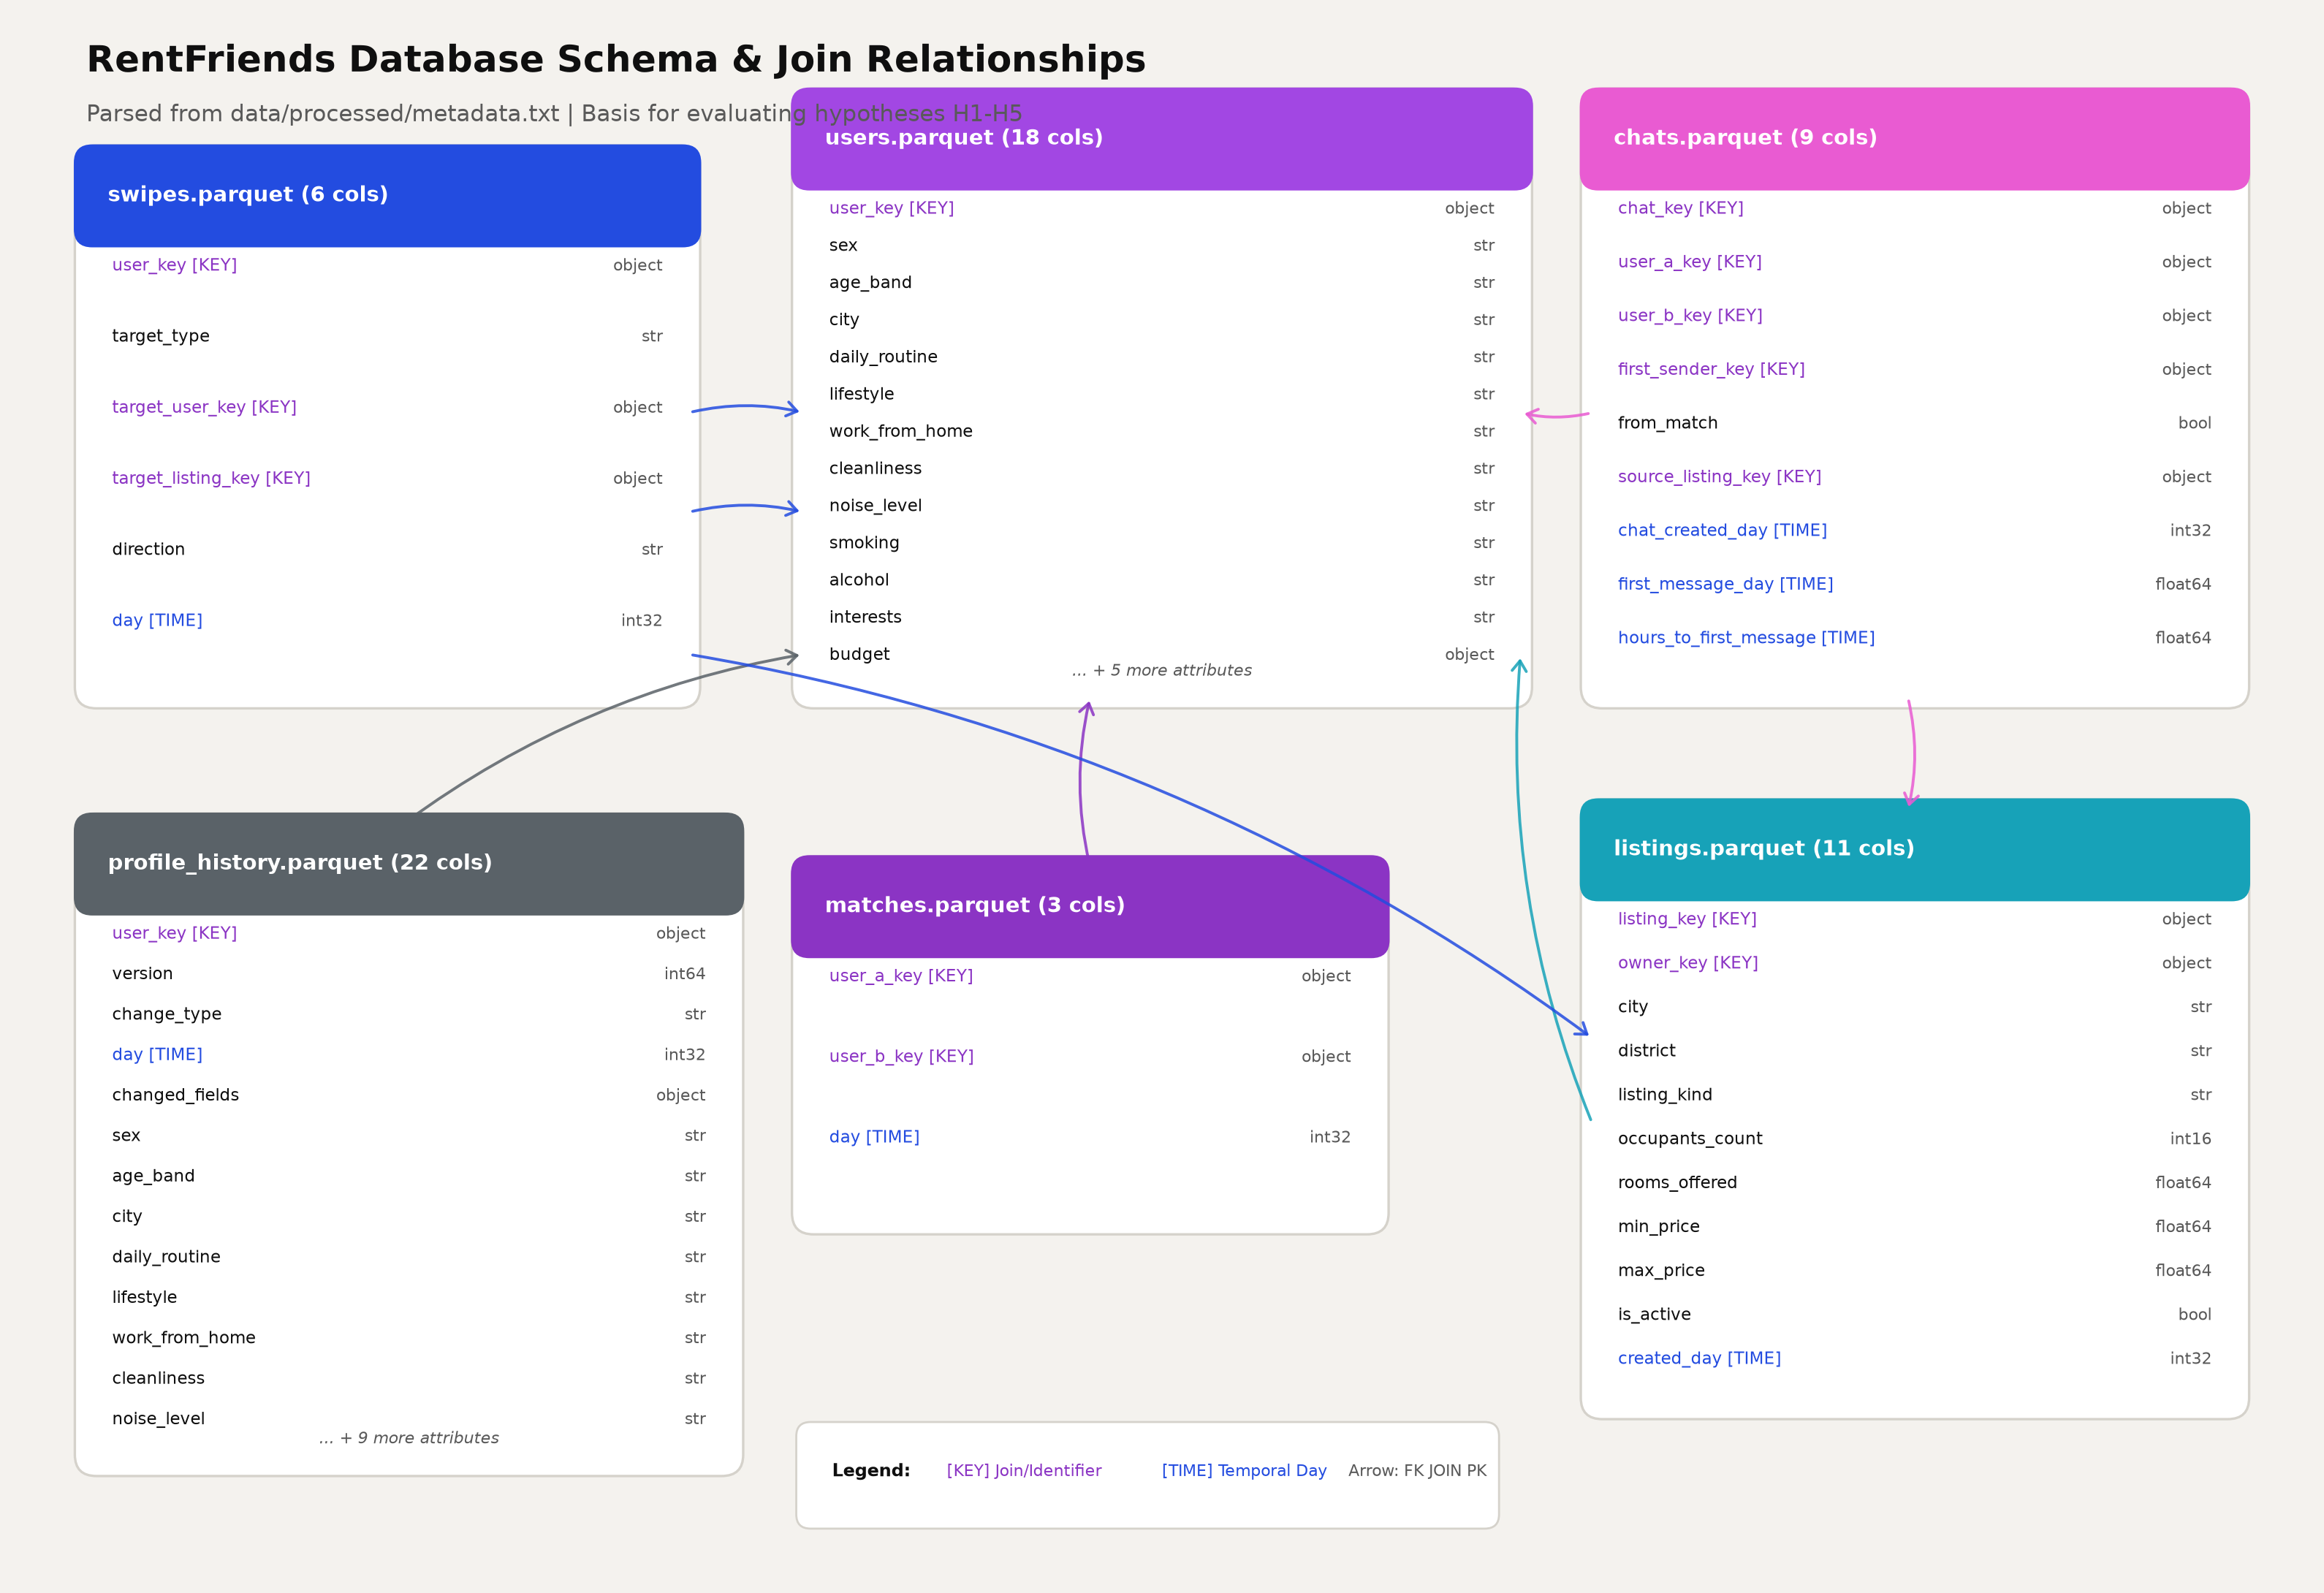


**Wnioski ze schematu:**
- W tabelach `swipes` i `matches` kolumna czasowa to wyłącznie **`day` (`int32`)**. Brakuje dokładnych znaczników czasu (godzin, minut, sekund).

- **Wpływ na H3:**
  - H3 zakłada estymację preferencji z historii swipe'ów *sprzed* danej decyzji: *„Preferencje użytkownika estymowane wyłącznie z jego swipe'ów **sprzed** danej decyzji (rozwijane okno)”*.
  - Jeśli użytkownik A i B wykonali akcje tego samego dnia, nie można ustalić kolejności bez ryzyka wycieku informacji z przyszłości (data leakage).
- **Wpływ na H4:**
  - H4 modeluje selektywność w czasie: *„odsetek prawych swipe'ów w oknie przed zdarzeniem”*.
  - Można policzyć selektywność per dzień kalendarzowy, ale nie da się precyzyjnie ustalić kolejności zdarzeń wewnątrz jednego dnia bez opierania się na arbitralnej kolejności wierszy.

> **Wniosek:** Dla H3 i H4 zostaje spełniony warunek wykluczenia **G3**. Wymagają one przeformułowania do wersji opartej na agregacji dziennej z uwzględnieniem remisów czasowych.

---

#### 2. Kwestia ziarnistości zmiennych (H1 & H2)

- **Wiek w H1 i H2:**
  - H1 i H2 planują numeryczne różnice wieku: `|Δ wiek|`, `Δ wiek`, `|Δ wiek|^2`.
  - W bazie dostępna jest zmienna kategorialna **`age_band` (`str`)**, a nie dokładny wiek w latach.
  - Jest to wciąż wykonalne, ale wymaga dopasowania przedziałowego (np. ta sama grupa / sąsiednia grupa) zamiast ciągłej różnicy wieku.

---

#### 3. Kryteria wykluczenia zależne od rozkładu danych (wymagają weryfikacji w EDA)

Struktura bazy pozwala na złączenie tabel, jednak dokumentacja definiuje reguły decyzyjne zależne od faktycznych wartości w rekordach:

1. **H2 (Warunek wstępny płci):**
   - *Reguła (Sekcja 5, pkt 4):* *„brak par różnopłciowych → H2 niewykonalna w proponowanej formie.”* Jeśli aplikacja serwuje w feedzie wyłącznie profile tej samej płci, $P(\text{prawy} \mid \text{różna płeć})$ nie ma wariancji.
2. **Liczebność próby i moc testów (H1–H5):**
   - *Reguła (Sekcja 5, pkt 1):* Jeśli liczba matchy $< 10 \times \text{liczba zmiennych}$, należy ograniczyć liczbę zmiennych w modelach.
3. **Wypełnienie bio (H5):**
   - *Reguła (Sekcja 5, pkt 7):* Niski odsetek niepustych bio ograniczy analizę H5b (podobieństwo semantyczne) wyłącznie do podpróby.

---

#### Podsumowanie statusu hipotez

| Hipoteza | Wykonalność strukturalna / złączenia | Status kryteriów wykluczenia |
|---|---|---|
| **H1** | Pełna (`users JOIN swipes / matches`) | **Wykonalna**, z uwzględnieniem `age_band` zamiast ciągłego wieku. |
| **H2** | Pełna (`users JOIN swipes`) | **Oczekuje na sprawdzenie danych**: Zależy od obecności par różnopłciowych w `swipes`. |
| **H3** | Pełna | **Kryterium G3 spełnione**: Brak dokładnych timestampów; wymaga przeformułowania do agregacji dziennej. |
| **H4** | Pełna | **Kryterium G3 spełnione**: Brak kolejności zdarzeń wewnątrz dnia; wymaga kroczącej agregacji dziennej. |
| **H5** | Pełna (`users / profile_history JOIN swipes / matches`) | **Gotowa strukturalnie**: `bio` i `bio_length` są dostępne w `users` i `profile_history`. Wykonalność zależy od stopnia wypełnienia tekstu. |

# Eksploracyjna analiza danych

In [ ]:
data_dir = "../data/processed/"

In [ ]:
import pandas as pd

users_df = pd.read_parquet(data_dir + "users.parquet")
chats_df = pd.read_parquet(data_dir + "chats.parquet")
listings_df = pd.read_parquet(data_dir + "listings.parquet")
swipes_df = pd.read_parquet(data_dir + "swipes.parquet")
matches_df = pd.read_parquet(data_dir + "matches.parquet")
profile_history_df = pd.read_parquet(data_dir + "profile_history.parquet")

In [ ]:
print(matches_df.shape[0])  # liczba matchy

Poniżej potwierdzenie, że wszystkie rekordy sa poprawne.

In [ ]:
matches_df.isna().mean() * 100

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
nans = users_df.isna().mean() * 100
print(str(users_df.shape[0]) + " zapisanych rekordów w users")
plt.bar(nans.index, nans.values)
plt.title("Procent NaN w poszczególnych kolumnach tabeli users")
plt.xticks(rotation=90)
plt.grid(alpha=0.5)
plt.show()

In [ ]:
users_df[users_df["bio_length"] > 0].shape[0]  # tutaj dokładna wartość liczby bio

In [ ]:
plt.hist(users_df[users_df["bio_length"] > 0]["bio_length"], bins=100)
# ">0" by odfiltrować rekordy bez bio
plt.title("Rozkład długości bio")
plt.grid()
plt.show()

In [ ]:
wynik = profile_history_df[
    profile_history_df["changed_fields"].str.contains("bio", regex=False, na=False)
]
print(f"Liczba odnotowanych modyfikacji bio w tabeli profile_history: {wynik.shape[0]}")

### Rozkłady zmiennych tabeli users

In [ ]:
plt.figure(figsize=(15, 30))
i = 1
for col in users_df.columns:
    if col in ("user_key", "interests", "bio", "bio_length", "budget", "move_in_month_offset"):
        continue
    plt.subplot(6, 2, i)
    counts = users_df[col].value_counts()
    plt.title(f"Rozkład kolumny {col} bez NaN")
    plt.grid()
    plt.bar(counts.index, counts.values)
    plt.xticks(rotation=20)
    i += 1
plt.show()

### Sprawdzenie warunku wstępnego dla H2
Warunek - wystarczajaca liczba par różnopłciowych.

In [ ]:
import pandas as pd

min_cross_sex_swipes = 1000  # criteria

# 1. Filter only profile-to-profile swipes (ignore listing swipes)
user_swipes = swipes_df.loc[
    swipes_df["target_type"] == "profile",
    ["user_key", "target_user_key", "direction"],
].copy()

In [ ]:
# 2. Join sender and target sexes
user_sex_map = users_df.set_index("user_key")["sex"]
user_swipes["sender_sex"] = user_swipes["user_key"].map(user_sex_map)
user_swipes["target_sex"] = user_swipes["target_user_key"].map(user_sex_map)

In [ ]:
# 3. Drop rows with missing sex declarations if any
valid_swipes = user_swipes.dropna(subset=["sender_sex", "target_sex"]).copy()
valid_swipes["is_right"] = (valid_swipes["direction"] == "right").astype(int)

In [ ]:
# 4. Total exposure matrix (Denominator: number of times pair was shown)
exposure_matrix = pd.crosstab(
    index=valid_swipes["sender_sex"],
    columns=valid_swipes["target_sex"],
    margins=True,
)

In [ ]:
# 5. Right-swipe acceptance rate matrix (Numerator / Denominator)
acceptance_matrix = valid_swipes.pivot_table(
    index="sender_sex",
    columns="target_sex",
    values="is_right",
    aggfunc="mean",
)

In [ ]:
# 6. Evaluation of the exclusion rule:
# Identify cross-sex pairings (where sender_sex != target_sex)
is_cross_sex = valid_swipes["sender_sex"] != valid_swipes["target_sex"]
cross_sex_total = int(is_cross_sex.sum())
cross_sex_right = int(valid_swipes.loc[is_cross_sex, "is_right"].sum())

In [ ]:
is_excluded = cross_sex_total < min_cross_sex_swipes

verdict = {
    "is_h2_feasible": not is_excluded,
    "cross_sex_swipes_count": cross_sex_total,
    "cross_sex_right_swipes": cross_sex_right,
    "cross_sex_acceptance_rate": (
        cross_sex_right / cross_sex_total if cross_sex_total > 0 else 0.0
    ),
    "exposure_matrix": exposure_matrix,
    "acceptance_matrix": acceptance_matrix,
    "reason": (
        "Exclusion criterion triggered: Insufficient cross-sex swipe exposure (G1 feed filter)."
        if is_excluded
        else "Sufficient cross-sex variance observed; H2 can be modeled."
    ),
}

In [ ]:
for k, v in verdict.items():
    print(k, v)

Poniżej wizualizacja macierzy

In [ ]:
import seaborn as sns

plt.figure(figsize=(15, 5))
ax = plt.subplot(1, 2, 1)
plt.title("Heeatmapa ekspozycji (wyświetleń)")
sns.heatmap(verdict["exposure_matrix"], annot=True, fmt="d", cmap="viridis", ax=ax)
ax = plt.subplot(1, 2, 2)
plt.title("Heatmapa akceptacji (procent)")
sns.heatmap(
    verdict["acceptance_matrix"] * 100, vmin=0.0, vmax=100.0, annot=True, cmap="viridis", ax=ax
)
plt.show()

### Odstęp czasowy między wzajemnymi swipe'ami
Czyli:
- Jaki procent swipe'ów miał miejsce tego samego dnia (nie da się ustalić kolejności)
- Po jakim czasie dochodzi do wzajmenego swipe'u

In [ ]:
import numpy as np

# 1. Filter only user swipes
user_swipes = swipes_df[swipes_df["target_type"] == "profile"][
    ["user_key", "target_user_key", "direction", "day"]
].copy()

# 2. Self-join to pair A->B with B->A
reciprocal = pd.merge(
    user_swipes,
    user_swipes,
    left_on=["user_key", "target_user_key"],
    right_on=["target_user_key", "user_key"],
    suffixes=("_A", "_B"),
)

# 3. Keep each pair only once (e.g. user_key_A < user_key_B)
reciprocal_unique = reciprocal[reciprocal["user_key_A"] < reciprocal["user_key_B"]].copy()

# 4. Compute temporal delta in days
reciprocal_unique["delta_days"] = (reciprocal_unique["day_B"] - reciprocal_unique["day_A"]).abs()

# 5. Share of same-day vs multi-day decisions
same_day_count = (reciprocal_unique["delta_days"] == 0).sum()
total_reciprocal = len(reciprocal_unique)
same_day_pct = (same_day_count / total_reciprocal) * 100

print(f"Total reciprocal pairs evaluated: {total_reciprocal}")
print(f"Swiped on the EXACT SAME DAY (delta=0): {same_day_count} ({same_day_pct:.2f}%)")
print(
    f"Swiped on DIFFERENT DAYS (delta > 0): {total_reciprocal - same_day_count}\
({100 - same_day_pct:.2f}%)"
)

# Distribution breakdown
print("\nDistribution of absolute delta in days:")
print(reciprocal_unique["delta_days"].value_counts(bins=[-1, 0, 1, 3, 7, 14, 30, 999]).sort_index())

Poniżej wykres do tego

In [ ]:
delta = reciprocal_unique["delta_days"].value_counts()
plt.bar(delta.index, delta.values)
plt.grid()
plt.title("Rozkład czasu na swipe zwrotny (w dniach)")
plt.show()

### Aktywność użytkowników (liczona w swipe'ach)

In [ ]:
# Filter profile swipes
u_swipes = swipes_df[swipes_df["target_type"] == "profile"].copy()
u_swipes["is_right"] = (u_swipes["direction"] == "right").astype(int)

# Group per user
user_activity = (
    u_swipes.groupby("user_key")
    .agg(
        total_swipes=("is_right", "count"),
        right_swipes=("is_right", "sum"),
        selectivity=("is_right", "mean"),
    )
    .reset_index()
)

# 1. Activity Quantiles
print("--- User Activity (Total Swipes per user) ---")
print(user_activity["total_swipes"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

# 2. Selectivity Distribution
print("\n--- User Selectivity (Right-swipe rate: right / total) ---")
print(user_activity["selectivity"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]))

# 3. Flag Extreme / Potential Bot Accounts (G10)
all_right_bots = (user_activity["selectivity"] == 1.0) & (user_activity["total_swipes"] >= 10)
all_left_users = (user_activity["selectivity"] == 0.0) & (user_activity["total_swipes"] >= 10)
low_activity = user_activity["total_swipes"] < 5

print(f"\nTotal active swipers: {len(user_activity)}")
print(
    f"Likely bots / extreme swipers (100% right, >=10 swipes): {all_right_bots.sum()}\
({all_right_bots.mean() * 100:.2f}%)"
)
print(
    f"Extreme rejecters (0% right, >=10 swipes): {all_left_users.sum()}\
({all_left_users.mean() * 100:.2f}%)"
)
print(
    f"Cold-start accounts (<5 total swipes): {low_activity.sum()}\
({low_activity.mean() * 100:.2f}%)"
)

Poniżej wizualizacja tych rozkładów

In [ ]:
plt.figure(figsize=(15, 5))
activity = user_activity["total_swipes"]
selectivity = user_activity["selectivity"]
plt.subplot(1, 2, 1)
plt.title("Rozkład aktywności użytkowników")
plt.xlabel("Liczba swipe'ów")
plt.hist(activity, bins=100)
plt.grid()
plt.subplot(1, 2, 2)
plt.title("Rozkład selektywności użytkowników")
plt.xlabel("stosunek prawych spiwe'ów do wszystkich swipe'ów")
plt.hist(selectivity, bins=20)
plt.grid()
plt.show()

### Sprawdzenie ekspozycji oraz stopnia akceptacji osób z różnych grup wiekowych w swipe'ach

In [ ]:
# Map age_band to sender and target
u_swipes = swipes_df[swipes_df["target_type"] == "profile"][
    ["user_key", "target_user_key", "direction"]
].copy()
age_map = users_df.set_index("user_key")["age_band"]

u_swipes["sender_age"] = u_swipes["user_key"].map(age_map)
u_swipes["target_age"] = u_swipes["target_user_key"].map(age_map)
u_swipes["is_right"] = (u_swipes["direction"] == "right").astype(int)

# Drop missing age bands if any
valid_age_swipes = u_swipes.dropna(subset=["sender_age", "target_age"])

# 1. Exposure Matrix (How many times did Sender Age see Target Age?)
age_exposure = pd.crosstab(
    index=valid_age_swipes["sender_age"],
    columns=valid_age_swipes["target_age"],
    margins=True,
)
print("=== Age Band Exposure Matrix (Counts) ===")
print(age_exposure)

# 2. Acceptance Matrix (What is P(right | sender_age, target_age)?)
age_acceptance = valid_age_swipes.pivot_table(
    index="sender_age", columns="target_age", values="is_right", aggfunc="mean"
)
print("\n=== Age Band Acceptance Rate (Mean P(right)) ===")
print((age_acceptance * 100).round(2).astype(str) + "%")

# 3. Same vs Different Age Band Comparison
valid_age_swipes["same_age_band"] = valid_age_swipes["sender_age"] == valid_age_swipes["target_age"]
print("\n=== Same vs Different Age Band Acceptance Rate ===")
print(valid_age_swipes.groupby("same_age_band")["is_right"].agg(["count", "mean"]))

In [ ]:
plt.figure(figsize=(15, 5))
ax = plt.subplot(1, 2, 1)
plt.title("Heeatmapa ekspozycji (wyświetleń)")
sns.heatmap(age_exposure, annot=True, fmt="d", cmap="viridis", ax=ax)
ax = plt.subplot(1, 2, 2)
plt.title("Heatmapa akceptacji (procent)")
sns.heatmap((age_acceptance * 100), vmin=0.0, vmax=100.0, annot=True, cmap="viridis", ax=ax)
plt.show()

### Analiza zainteresowań użytkowników

In [ ]:
import ast


# Helper to parse stringified tags (e.g., "['sport', 'music']" or "sport, music")
def parse_tags(val):
    if pd.isna(val) or not val:
        return set()
    if isinstance(val, list | set):
        return set(val)
    val_str = str(val).strip()
    if val_str.startswith("[") and val_str.endswith("]"):
        try:
            return set(ast.literal_eval(val_str))
        except Exception:
            pass
    # Fallback comma-separated
    return {tag.strip().lower() for tag in val_str.split(",") if tag.strip()}


# 1. Parse interests per user
interests_series = users_df.set_index("user_key")["interests"].apply(parse_tags)
tag_counts = interests_series.apply(len)

print("=== User Interests Tag Counts ===")
print(f"Empty interests rate: {(tag_counts == 0).mean() * 100:.2f}%")
print(tag_counts.describe(percentiles=[0.25, 0.5, 0.75, 0.9]))

# Vocabulary of tags
all_tags = [tag for tags in interests_series for tag in tags]
vocab_series = pd.Series(all_tags).value_counts()
print(f"\nUnique interest tags found: {len(vocab_series)}")
print("Top 10 most popular tags:")
print(vocab_series.head(10))

# 2. Jaccard similarity on matched pairs
matches_clean = matches_df.copy()
matches_clean["tags_A"] = matches_clean["user_a_key"].map(interests_series)
matches_clean["tags_B"] = matches_clean["user_b_key"].map(interests_series)


def compute_jaccard(row):
    set_a, set_b = row["tags_A"], row["tags_B"]
    if not isinstance(set_a, set) or not isinstance(set_b, set):
        return np.nan
    union = len(set_a | set_b)
    if union == 0:
        return 0.0
    return len(set_a & set_b) / union


matches_clean["jaccard"] = matches_clean.apply(compute_jaccard, axis=1)

print("\n=== Jaccard Similarity Distribution on Matched Pairs ===")
print(matches_clean["jaccard"].describe())
print(
    f"Share of matched pairs with 0 shared tags:\
{(matches_clean['jaccard'] == 0).mean() * 100:.2f}%"
)

Poniżej wizualizacje rozkładów

In [ ]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.grid()
plt.title("Rozkład liczby zainteresowań w profilach użytkowników")
plt.hist(tag_counts, bins=19)
plt.subplot(1, 2, 2)
plt.grid()
plt.title("Podobieństwo Jaccard w zainteresowaniach między zmatchowanymi użytkownikami")
plt.hist(matches_clean["jaccard"], bins=50)
plt.show()

plt.figure(figsize=(15, 5))
plt.title("Najpopularniejsze zainteresowania deklarowane przez użytkowników")
plt.bar(vocab_series.head(20).index, vocab_series.head(20).values)
plt.xticks(rotation=45)
plt.grid()
plt.show()

### Odsiew użytkowników - poczawszy od pierwszego swipe'a aż do rozpoczętej konwersacji

In [ ]:
# 1. Base counts
total_profile_swipes = len(swipes_df[swipes_df["target_type"] == "profile"])
right_swipes_count = len(
    swipes_df[(swipes_df["target_type"] == "profile") & (swipes_df["direction"] == "right")]
)
total_matches = len(matches_df)

# 2. Chats originated from matches
# (chats.parquet has 'from_match' boolean flag)
chats_from_matches = chats_df[chats_df["from_match"]]
total_chats_from_match = len(chats_from_matches)

# Distinct matched pairs who actually started a chat
# Normalize pair keys to order-invariant tuple
chat_pairs = set(
    chats_from_matches.apply(lambda r: tuple(sorted([r["user_a_key"], r["user_b_key"]])), axis=1)
)
matched_pairs = set(
    matches_df.apply(lambda r: tuple(sorted([r["user_a_key"], r["user_b_key"]])), axis=1)
)
matches_with_chat = len(matched_pairs.intersection(chat_pairs))

# 3. Funnel Summary Table
funnel_data = {
    "Stage": [
        "1. Profile Swipes (Total)",
        "2. Right Swipes (Interest)",
        "3. Mutual Matches (Pairs)",
        "4. Matches with Chat Started",
    ],
    "Count": [
        total_profile_swipes,
        right_swipes_count,
        total_matches,
        matches_with_chat,
    ],
}
funnel_df = pd.DataFrame(funnel_data)
funnel_df["Conv. from Previous"] = [
    "100.0%",
    f"{(right_swipes_count / total_profile_swipes) * 100:.2f}%",
    # Each match requires at least 2 right swipes
    f"{(total_matches * 2 / right_swipes_count) * 100:.2f}% (of right swipes)",
    f"{(matches_with_chat / total_matches) * 100:.2f}%",
]
funnel_df["Conv. from Start"] = (funnel_df["Count"] / total_profile_swipes * 100).map(
    "{:.4f}%".format
)

print("=== RentFriends Conversion Funnel ===")
print(funnel_df.to_string(index=False))

# Uzupełnienie pól `[DO UZUPEŁNIENIA]` z karty eksploracji

Poniższe komórki liczą wskaźniki, których brakowało w [docs/rentfriends_hipotezy_karta_eksploracji.md](../docs/rentfriends_hipotezy_karta_eksploracji.md): zakres czasowy, rozmowy spoza matchy, pola stylu życia, liczność prób po filtrach, statystyki bio, przedziały ufności dla H2 oraz powiązanie swipe'ów z ogłoszeniami.

### Zakres czasowy danych
Pole `day` jest numerem dnia (int32). Sprawdzamy zakres w każdej tabeli oraz dzienną aktywność.

In [ ]:
day_cols = [
    ("swipes", swipes_df, "day"),
    ("matches", matches_df, "day"),
    ("chats (utworzenie)", chats_df, "chat_created_day"),
    ("profile_history", profile_history_df, "day"),
    ("listings (utworzenie)", listings_df, "created_day"),
]
for name, frame, col in day_cols:
    print(
        f"{name:22s} dni {frame[col].min()} .. {frame[col].max()} "
        f"({frame[col].nunique()} różnych dni)"
    )

all_days = range(int(swipes_df["day"].min()), int(swipes_df["day"].max()) + 1)
daily_swipes = (
    swipes_df.groupby(["day", "target_type"])
    .size()
    .unstack(fill_value=0)
    .reindex(all_days, fill_value=0)
)
daily_matches = matches_df.groupby("day").size().reindex(all_days, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
daily_swipes.plot(ax=axes[0])
axes[0].set_title("Swipe'y dziennie (profile vs ogłoszenia)")
axes[0].set_xlabel("day")
axes[0].grid(alpha=0.5)
axes[1].bar(daily_matches.index, daily_matches.values)
axes[1].set_title("Matche dziennie")
axes[1].set_xlabel("day")
axes[1].grid(alpha=0.5)
plt.show()

### Rozmowy spoza matchu (pytanie o Superlajk, sekcja 2.2 pkt 8)
Tabela `chats` ma flagę `from_match`. Sprawdzamy, ile rozmów powstało bez matchu i czy mają źródłowe ogłoszenie.

In [ ]:
chat_source = np.select(
    [chats_df["from_match"], chats_df["source_listing_key"].notna()],
    ["z matcha", "z ogłoszenia (bez matcha)"],
    default="inne (bez matcha i ogłoszenia)",
)
chat_source_counts = pd.Series(chat_source).value_counts()
print(chat_source_counts)
print(f"\nŁącznie rozmów: {len(chats_df)}, z matcha: {chats_df['from_match'].mean() * 100:.2f}%")

plt.figure(figsize=(8, 4))
plt.barh(chat_source_counts.index, chat_source_counts.values)
plt.title("Źródło rozmów")
plt.grid(alpha=0.5)
plt.show()

### Pola stylu życia: kompletność i wartości domyślne
Pola strukturalne w `users` (poza `interests` i `bio`). Duży udział jednej kategorii przy prawie zerowych brakach (`cleanliness`, `noise_level`) może oznaczać wartość domyślną w aplikacji. To trzeba potwierdzić z dostawcą.

In [ ]:
profile_cols = [
    "daily_routine",
    "lifestyle",
    "work_from_home",
    "cleanliness",
    "noise_level",
    "smoking",
    "alcohol",
    "room_type",
    "budget",
    "move_in_month_offset",
    "city",
    "search_goal",
]
completeness = pd.DataFrame(
    {
        "missing_pct": users_df[profile_cols].isna().mean() * 100,
        "n_categories": users_df[profile_cols].nunique(),
        "top_category_share_pct": [
            users_df[c].value_counts(normalize=True).iloc[0] * 100 for c in profile_cols
        ],
    }
).round(1)
print(completeness)

# Number of structured fields filled in per user
filled = users_df[profile_cols].notna().sum(axis=1)
print("\nLiczba wypełnionych pól na użytkownika:")
print(filled.describe(percentiles=[0.25, 0.5, 0.75]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
completeness["missing_pct"].sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Odsetek braków w polach strukturalnych (%)")
axes[0].grid(alpha=0.5)
axes[1].hist(filled, bins=range(0, len(profile_cols) + 2), align="left")
axes[1].set_title("Liczba wypełnionych pól na użytkownika")
axes[1].grid(alpha=0.5)
plt.show()

for col in ["cleanliness", "noise_level"]:
    print(f"\nRozkład {col} (%):")
    print((users_df[col].value_counts(normalize=True, dropna=False) * 100).round(1))

### Wspólna baza par z decyzją obu stron
Swipe'y na profile bez duplikatów, z liczbą wcześniejszych swipe'ów nadawcy (`prior_n`, tylko z wcześniejszych dni, bo kolejność w obrębie dnia jest nieznana). Pary {A,B}, w których obie strony zdecydowały, wraz z flagą matcha. Baza służy kolejnym komórkom.

In [ ]:
prof = swipes_df.loc[
    swipes_df["target_type"] == "profile", ["user_key", "target_user_key", "direction", "day"]
].copy()
n_dup = prof.duplicated(["user_key", "target_user_key"]).sum()
print(f"Zduplikowane swipe'y (ta sama para nadawca-odbiorca): {n_dup}")
prof = prof.drop_duplicates(["user_key", "target_user_key"])
prof["is_right"] = (prof["direction"] == "right").astype(int)

# prior_n = sender's swipes made on strictly earlier days
day_counts = prof.groupby(["user_key", "day"]).size().rename("n").reset_index()
day_counts = day_counts.sort_values(["user_key", "day"])
day_counts["prior_n"] = day_counts.groupby("user_key")["n"].cumsum() - day_counts["n"]
prof = prof.merge(day_counts[["user_key", "day", "prior_n"]], on=["user_key", "day"])

pairs = prof.merge(
    prof,
    left_on=["user_key", "target_user_key"],
    right_on=["target_user_key", "user_key"],
    suffixes=("_A", "_B"),
)
pairs = pairs[pairs["user_key_A"] < pairs["user_key_B"]].copy()
pairs["delta_days"] = (pairs["day_A"] - pairs["day_B"]).abs()

match_set = set(map(tuple, np.sort(matches_df[["user_a_key", "user_b_key"]].to_numpy(), axis=1)))
pairs["is_match"] = [
    (a, b) in match_set for a, b in zip(pairs["user_key_A"], pairs["user_key_B"], strict=True)
]
both_right = (pairs["is_right_A"] == 1) & (pairs["is_right_B"] == 1)
print(
    f"Pary z decyzją obu stron: {len(pairs)}, "
    f"z matchem: {pairs['is_match'].sum()} z {len(matches_df)}"
)
print(
    f"Zgodność matcha z wzajemnym prawym swipe'em: "
    f"{(both_right == pairs['is_match']).mean() * 100:.2f}%"
)

# Accounts with extreme selectivity (G10), as in the activity section
act = prof.groupby("user_key")["is_right"].agg(["count", "mean"])
extreme_users = set(act[(act["count"] >= 10) & (act["mean"].isin([0.0, 1.0]))].index)
print(f"Konta skrajne (0% lub 100% prawo, >= 10 swipe'ów): {len(extreme_users)}")

### Matche bez kompletu swipe'ów
Match powinien wynikać z dwóch prawych swipe'ów na profile. Sprawdzamy, dla ilu matchy w `swipes` są oba swipe'e, a dla ilu tylko jeden (drugi mógł powstać innym mechanizmem, np. zaproszeniem; to pytanie do dostawcy). Ma to wpływ na liczbę matchy dostępnych w modelach opartych na parach z decyzją obu stron.

In [ ]:
swipe_dir = {
    (a, b): (d, dy)
    for a, b, d, dy in zip(
        prof["user_key"], prof["target_user_key"], prof["direction"], prof["day"], strict=True
    )
}
coverage = []
for a, b in zip(matches_df["user_a_key"], matches_df["user_b_key"], strict=True):
    ab, ba = swipe_dir.get((a, b)), swipe_dir.get((b, a))
    if ab and ba:
        coverage.append("oba swipe'y")
    elif ab or ba:
        coverage.append("tylko jeden swipe")
    else:
        coverage.append("brak swipe'ów")
coverage = pd.Series(coverage).value_counts()
print(coverage)
print((coverage / coverage.sum() * 100).round(1))

plt.figure(figsize=(7, 4))
plt.bar(coverage.index, coverage.values)
plt.title("Matche wg dostępnych swipe'ów na profile")
plt.grid(alpha=0.5)
plt.show()

### Liczność prób po filtrach aktywności (H1, H3, H4)
Dla progów `n_min` liczymy:
- swipe'y, w których nadawca miał wcześniej (w poprzednich dniach) co najmniej `n_min` swipe'ów (próba H3),
- pary z decyzją obu stron, gdzie obie strony miały taką historię i zdecydowały w różne dni (H3/H4),
- pary z progiem łącznej aktywności (≥ `n_min` swipe'ów w całych danych, wariant H1),
- osobno wariant bez kont skrajnych.

In [ ]:
total_swipes = prof.groupby("user_key").size()
rows = []
for n_min in [0, 5, 10, 20, 30, 50]:
    hist_ok = (pairs["prior_n_A"] >= n_min) & (pairs["prior_n_B"] >= n_min)
    diff_day = pairs["delta_days"] > 0
    total_ok = (pairs["user_key_A"].map(total_swipes) >= n_min) & (
        pairs["user_key_B"].map(total_swipes) >= n_min
    )
    not_extreme = ~(
        pairs["user_key_A"].isin(extreme_users) | pairs["user_key_B"].isin(extreme_users)
    )
    rows.append(
        {
            "n_min": n_min,
            "H3 swipe'y z historią": int((prof["prior_n"] >= n_min).sum()),
            "H3/H4 pary (historia, różne dni)": int((hist_ok & diff_day).sum()),
            "H3/H4 matche": int((hist_ok & diff_day & pairs["is_match"]).sum()),
            "H3/H4 pary bez skrajnych": int((hist_ok & diff_day & not_extreme).sum()),
            "H1 pary (łączna aktywność)": int(total_ok.sum()),
            "H1 matche": int((total_ok & pairs["is_match"]).sum()),
            "H1 pary bez skrajnych": int((total_ok & not_extreme).sum()),
        }
    )
filter_table = pd.DataFrame(rows).set_index("n_min")
print(filter_table.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
filter_table[["H3/H4 pary (historia, różne dni)", "H1 pary (łączna aktywność)"]].plot(
    marker="o", ax=axes[0]
)
axes[0].set_title("Liczba par po filtrze n_min")
axes[1].plot(filter_table.index, filter_table["H3/H4 matche"], marker="o", label="H3/H4 matche")
axes[1].plot(filter_table.index, filter_table["H1 matche"], marker="o", label="H1 matche")
axes[1].axhline(10 * 10, color="gray", ls="--", label="próg 10 matchy × 10 zmiennych")
axes[1].set_title("Liczba matchy po filtrze n_min")
axes[1].set_xlabel("n_min")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.5)
plt.show()

### Bio: statystyki długości i pokrycie par (H5)
Mediana i IQR długości niepustego bio oraz liczba par (z decyzją obu stron, matchy i swipe'ów skierowanych), w których bio jest niepuste po obu stronach lub po stronie odbiorcy.

In [ ]:
has_bio = users_df.set_index("user_key")["bio_length"].fillna(0) > 0
bio_len = users_df.loc[users_df["bio_length"] > 0, "bio_length"]
print(f"Niepuste bio: {has_bio.sum()} z {len(has_bio)} ({has_bio.mean() * 100:.1f}%)")
print(bio_len.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1))

pairs_bio = pairs["user_key_A"].map(has_bio).fillna(False) & pairs["user_key_B"].map(
    has_bio
).fillna(False)
match_bio = matches_df["user_a_key"].map(has_bio).fillna(False) & matches_df["user_b_key"].map(
    has_bio
).fillna(False)
target_bio = prof["target_user_key"].map(has_bio).fillna(False)

print(f"\nPary z decyzją obu stron, oba bio niepuste: {pairs_bio.sum()} z {len(pairs)}")
print(f"  w tym matche: {(pairs_bio & pairs['is_match']).sum()}")
print(f"Matche z oboma bio niepustymi: {match_bio.sum()} z {len(matches_df)}")
print(f"Swipe'y na profil z niepustym bio (H5a): {target_bio.sum()} z {len(prof)}")

# Right-swipe rate by receiver's bio presence (descriptive only)
print("\nOdsetek prawych swipe'ów wg obecności bio odbiorcy:")
print(
    prof.groupby(target_bio)["is_right"]
    .agg(["count", "mean"])
    .rename(index={False: "brak bio", True: "bio"})
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(np.log10(bio_len), bins=40)
axes[0].set_title("Rozkład długości bio (log10 znaków, tylko niepuste)")
axes[0].grid(alpha=0.5)
axes[1].boxplot(bio_len, vert=False)
axes[1].set_title("Długość bio (znaki, tylko niepuste)")
axes[1].grid(alpha=0.5)
plt.show()

### H2: przedziały ufności dla P(prawy swipe) wg płci nadawcy i odbiorcy
Przedziały Wilsona (95%) dla każdej komórki macierzy płeć nadawcy × płeć odbiorcy. Pozwalają ustalić z góry próg „bliskie zeru” dla P(prawy | różna płeć) z uwzględnieniem niepewności; to decyzja badawcza, nie wynik. Uwaga: swipe'y tego samego użytkownika nie są niezależne, więc przedziały są zaniżone (docelowo błędy klastrowane po użytkowniku).

In [ ]:
sex_map = users_df.set_index("user_key")["sex"]
sw = prof.assign(
    sender_sex=prof["user_key"].map(sex_map), target_sex=prof["target_user_key"].map(sex_map)
).dropna(subset=["sender_sex", "target_sex"])


def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


cell_stats = (
    sw.groupby(["sender_sex", "target_sex"])["is_right"].agg(["sum", "count"]).reset_index()
)
cell_stats["p"] = cell_stats["sum"] / cell_stats["count"]
bounds = [wilson(k, n) for k, n in zip(cell_stats["sum"], cell_stats["count"], strict=True)]
cell_stats["lo"] = [b[0] for b in bounds]
cell_stats["hi"] = [b[1] for b in bounds]
print(cell_stats.round(3).to_string(index=False))

# Pooled: cross-sex vs same-sex, per sender sex
sw["pair_type"] = np.where(sw["sender_sex"] == sw["target_sex"], "ta sama płeć", "różna płeć")
pooled = sw.groupby(["sender_sex", "pair_type"])["is_right"].agg(["sum", "count"]).reset_index()
pooled["p"] = pooled["sum"] / pooled["count"]
pb = [wilson(k, n) for k, n in zip(pooled["sum"], pooled["count"], strict=True)]
pooled["lo"] = [b[0] for b in pb]
pooled["hi"] = [b[1] for b in pb]
print("\nWg płci nadawcy i typu pary:")
print(pooled.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
labels = cell_stats["sender_sex"] + "→" + cell_stats["target_sex"]
ax.errorbar(
    range(len(cell_stats)),
    cell_stats["p"] * 100,
    yerr=[(cell_stats["p"] - cell_stats["lo"]) * 100, (cell_stats["hi"] - cell_stats["p"]) * 100],
    fmt="o",
    capsize=4,
)
ax.set_xticks(range(len(cell_stats)))
ax.set_xticklabels(labels)
ax.set_ylabel("P(prawy swipe) [%] z 95% CI Wilsona")
ax.set_title("Akceptacja wg płci nadawcy i odbiorcy")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.5)
plt.show()

### Swipe'y na ogłoszenia: powiązanie z cechami ogłoszeń (sekcja 2.2 pkt 7)
Sprawdzamy, czy `target_listing_key` łączy się z `listings`, oraz opisujemy cechy ogłoszeń i akceptację wg miasta.

In [ ]:
ls = swipes_df.loc[
    swipes_df["target_type"] == "listing", ["user_key", "target_listing_key", "direction", "day"]
].copy()
ls["is_right"] = (ls["direction"] == "right").astype(int)
ls = ls.merge(listings_df, left_on="target_listing_key", right_on="listing_key", how="left")
print(
    f"Swipe'y na ogłoszenia: {len(ls)}, "
    f"powiązane z listings: {ls['listing_key'].notna().mean() * 100:.2f}%"
)
print(
    f"Unikalne ogłoszenia ze swipe'ami: {ls['target_listing_key'].nunique()} z {len(listings_df)}"
)
print(f"Odsetek prawych swipe'ów na ogłoszenia: {ls['is_right'].mean() * 100:.2f}%")
print(
    f"Swipe'y na ogłoszenia na użytkownika (mediana): {ls.groupby('user_key').size().median():.0f}"
)

print("\nCechy ogłoszeń:")
print(
    listings_df[["occupants_count", "rooms_offered", "min_price", "max_price"]].describe().round(1)
)
print(listings_df["listing_kind"].value_counts(dropna=False))

# Same city as the swiping user vs different
ls["user_city"] = ls["user_key"].map(users_df.set_index("user_key")["city"])
ls["same_city"] = ls["user_city"] == ls["city"]
print("\nAkceptacja: to samo miasto vs inne:")
print(ls.groupby("same_city")["is_right"].agg(["count", "mean"]))

by_city = ls.groupby("city")["is_right"].agg(["count", "mean"]).query("count >= 100")
price = listings_df["min_price"].dropna()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(by_city.index, by_city["mean"] * 100)
axes[0].set_title("Odsetek prawych swipe'ów na ogłoszenia wg miasta (n >= 100)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(alpha=0.5)
axes[1].hist(price[price <= price.quantile(0.99)], bins=40)
axes[1].set_title("Rozkład min_price ogłoszeń (do 99. percentyla)")
axes[1].grid(alpha=0.5)
plt.show()